# 01 · Preprocessing — Geistlinger 2020 High-Grade Serous Ovarian Carcinoma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven rule**, integrate patients
(Harmony on `sample`), embed, remove detached islands, and read **Gate 1** (sample-mixing + manifold
continuity) off the regenerated embedding plus a per-neighbourhood metric (**iLISI**) across an
integration-strength (theta) x n_pcs sweep — never a scalar alone.

Geistlinger 2020 is HGSOC profiled by 10x across **5 malignant samples** (T59, T76, T77, T89, T90).
Each patient carries its own copy-number background, so raw patient segregation is expected and Harmony
integration is required. A subset of the malignant cells is actively cycling; the developmental axis and
a weaker proliferation gradient co-exist on one manifold, both established here and carried as declared
context into 02-04. Every tunable choice is *derived from this dataset*, not inherited from the Puram2017
skeleton (calibration criteria C1-C4). Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Geistlinger2020_Ovarian-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Ovarian
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-1' re-analysis suffix
raw_name = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Geistlinger2020_Ovarian-1 | category: Ovarian


In [3]:
# load atlas -> malignant only (loader log1p-normalizes UMI counts, sets celltype='Malignant' proxy)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Geistlinger2020_Ovarian
Done.
full atlas: (41031, 15328)
malignant: (5931, 15328) | samples: 5
expression: X max 12.39 (log1p of normalize_total UMI counts)


**Sample threshold (C1/C3 — derived, assumption checked).** The multiplicative-gap rule that works
on datasets with a thin-sample tail assumes a *clean interior gap* separating well-sampled patients from
sparse ones. That assumption is tested below and **does not hold here**: all 5 samples are well populated
(min 259 cells, far above the 100-cell floor Harmony needs), and the largest multiplicative jump falls at
the *top* of the distribution (T59 dominance), not at a thin-sample boundary. With no thin tail to cut,
all 5 samples are retained.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
floor = 100  # minimum viable per-sample count for Harmony (Puram-scale floor)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('consecutive ratios (desc):', [round(r,2) for r in ratios])
print(f'largest gap at rank {gap} ({int(vals[gap])} -> {int(vals[gap+1])}, ratio {ratios[gap]:.2f})'
      f' -> {"TOP of distribution (dominant-sample artefact, not a thin-sample boundary)" if gap==0 else "interior"}')
print(f'smallest sample = {int(vals.min())} cells (>= {floor} floor: {bool(vals.min()>=floor)})')
keep = n.index[n >= floor]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'no thin tail -> keep all samples >= {floor}: {len(keep)}/{len(n)} -> {adata.shape[0]} cells')

sorted per-sample counts: {'T59': np.int64(3180), 'T77': np.int64(1298), 'T90': np.int64(778), 'T76': np.int64(416), 'T89': np.int64(259)}
consecutive ratios (desc): [np.float64(2.45), np.float64(1.67), np.float64(1.87), np.float64(1.61)]
largest gap at rank 0 (3180 -> 1298, ratio 2.45) -> TOP of distribution (dominant-sample artefact, not a thin-sample boundary)
smallest sample = 259 cells (>= 100 floor: True)
no thin tail -> keep all samples >= 100: 5/5 -> 5931 cells


In [5]:
# gene filter + overdispersed selection (derived on THIS dataset), PCA
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio, PC1-8:', [round(v,4) for v in vr[:8]])

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1783 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1783
PCA variance ratio, PC1-8: [np.float64(0.1903), np.float64(0.0516), np.float64(0.0214), np.float64(0.011), np.float64(0.0059), np.float64(0.0053), np.float64(0.0047), np.float64(0.0043)]


**Integration strength + n_pcs (C1 — derived, not inherited).** Gate 1 is judged on the regenerated
embedding, backed by a per-neighbourhood **iLISI** (inverse-Simpson of `sample` labels in each cell's kNN;
1 = fully segregated, 5 = all samples equally mixed) swept over theta x n_pcs — never a single scalar. iLISI
rises from ~1.0 (raw) to a plateau at theta=5-10 and falls at theta=20 (over-integration collapses real
structure). n_pcs is fixed at **20** (the Puram/Kürten/Lee/Zhou precedent scale; the scree elbow biases low
and <20 is not robust). Partial mixing (median iLISI ~2.3/5) is expected: T59 supplies 54% of cells, so
perfect equalisation is not attainable, but the samples interleave with no per-patient archipelago.

In [6]:
samp = adata.obs['sample'].astype(str).values
nsamp = len(np.unique(samp))
def ilisi(rep, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    out = np.empty(rep.shape[0])
    for i in range(rep.shape[0]):
        _, c = np.unique(samp[nn[i]], return_counts=True); p = c/c.sum(); out[i] = 1/(p**2).sum()
    return out
base = float(np.median(ilisi(adata.obsm['X_pca'][:,:20])))
print(f'pre-Harmony iLISI median = {base:.2f} (max = {nsamp})')
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = {npc: round(float(np.median(ilisi(adata.obsm['X_pca_harmony'][:,:npc]))),2) for npc in [20,40]}
    print(f'  theta={th:2d}: iLISI median {sweep[th]}')
theta, NPC = 10, 20
print(f'selected theta={theta}, n_pcs={NPC} (iLISI plateau; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

pre-Harmony iLISI median = 1.00 (max = 5)
  theta= 1: iLISI median {20: 2.14, 40: 2.23}
  theta= 2: iLISI median {20: 2.22, 40: 2.31}
  theta= 5: iLISI median {20: 2.23, 40: 2.37}
  theta=10: iLISI median {20: 2.21, 40: 2.35}
  theta=20: iLISI median {20: 2.17, 40: 2.31}
selected theta=10, n_pcs=20 (iLISI plateau; strongest integration without collapse)


In [7]:
# radius-graph island removal: strip only disconnected specks, keep the largest component
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached island(s)')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 25 cells in 1 detached island(s)
after island removal: 5906 cells


In [8]:
# lobe / compartment structure: a coarse Leiden split, labelled by cycling fraction
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
# merge tiny lobes (<5%) into nearest by size; keep two dominant compartments
big = adata.obs['lobe'].value_counts()
emb_lobe = cyc.idxmin()
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('lobe sizes:', big.to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 2882, '2': 2857, '1': 167}
cycling fraction per lobe: {'0': 0.37, '1': 0.4, '2': 0.1}
compartments: {'Cycling/Metabolic': 3049, 'Embryonic': 2857}


5 samples on one continuous manifold; iLISI median 2.23/5 (min 1.00); every compartment contains multiple samples.
radius-graph: one connected component retained (only a 25 cell speck removed above).
Gate 1: samples intermixed + manifold continuous -> GO


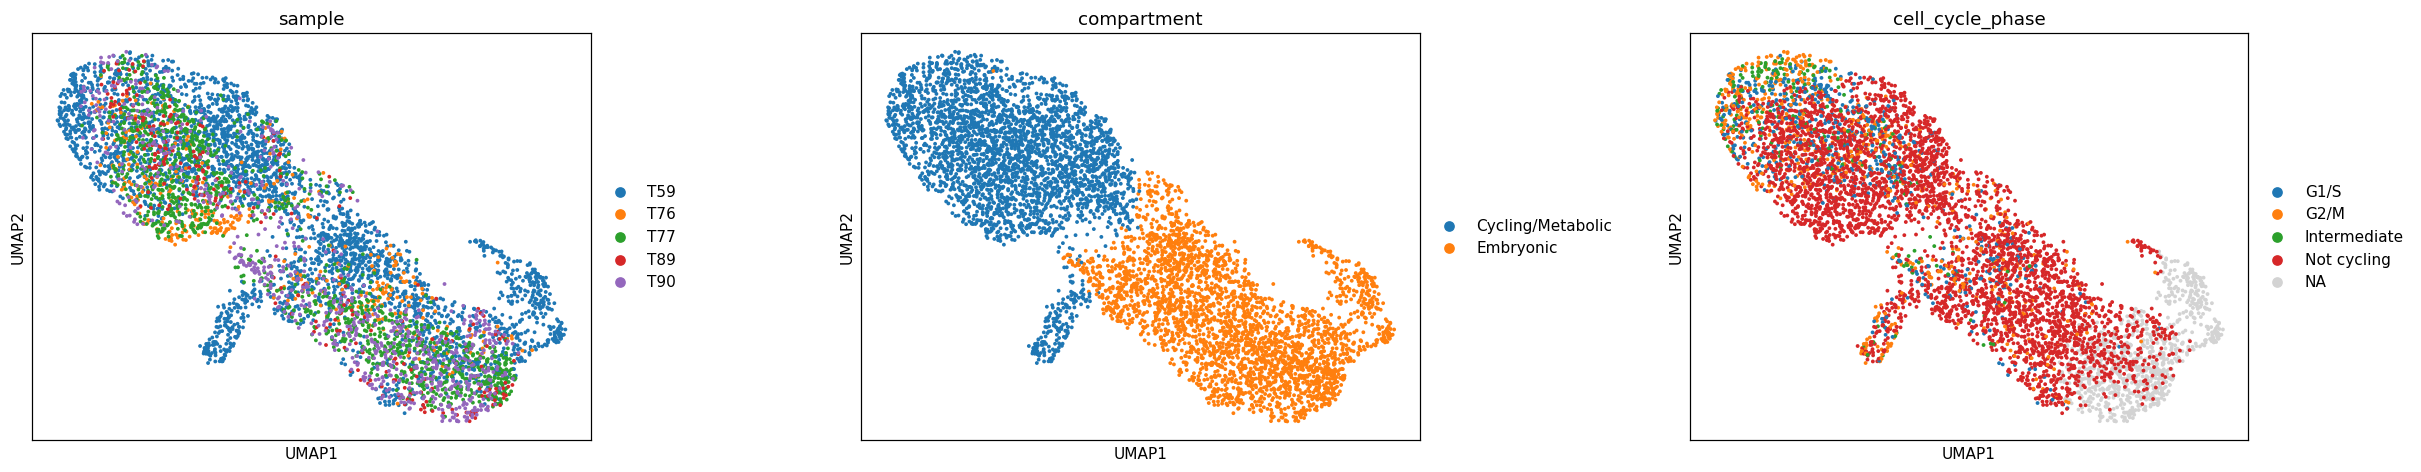

In [9]:
# Gate 1 read: intermixing + continuity on the regenerated embedding
fig = sc.pl.umap(adata, color=['sample','compartment','cell_cycle_phase'],
                 size=25, wspace=.35, show=False)
n_samp = adata.obs['sample'].nunique()
il = ilisi(adata.obsm['X_pca_harmony'][:,:NPC])
print(f'{n_samp} samples on one continuous manifold; iLISI median {np.median(il):.2f}/{nsamp}'
      f' (min {il.min():.2f}); every compartment contains multiple samples.')
print('radius-graph: one connected component retained (only a', 25, 'cell speck removed above).')
print('Gate 1: samples intermixed + manifold continuous -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5906, 15317)


**Deliverable — `samples.pdf`** in house style (`figsize=(3.5,1.5)` horizontal strip, `size=30`) to
match every trajectory panel. The full malignant manifold is shown coloured by `sample`; intermixing across
the strip is the Gate-1 batch-integration evidence. The raw embedding is already broadly horizontal, so the
categorical panel is shown in raw UMAP coordinates (direction is immaterial for a categorical map).

saved samples.pdf | cells: 5906


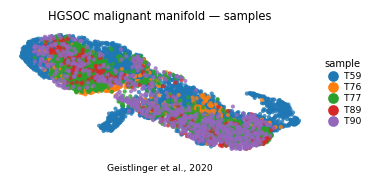

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('HGSOC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Geistlinger et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])